# Лабораторная работа №1. Регрессионный анализ

**Студент:** Васютинский Вадим Александрович
**Вариант:** 8 (`lab1-08.csv`)

**Цель:** научиться применять модели линейной регрессии библиотеки scikit-learn к набору эмпирических данных.

**Результат:** эмпирическая формула зависимости $y(x)$.

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split, GridSearchCV, KFold
from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import PolynomialFeatures, FunctionTransformer
from sklearn.pipeline import Pipeline
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

RANDOM_STATE = 42
DATA_PATH = Path('..') / '..' / 'tasks' / 'lab1' / 'dataset' / 'lab1-08.csv'

## 1. Загрузка данных

In [2]:
data = pd.read_csv(DATA_PATH, header=None, names=['x', 'y'])
data.head()

,x,y
0,7.393939,-4.832168
1,-2.595960,21.935301
2,-1.030303,8.319461
3,7.454545,-3.898417
4,-2.292929,16.866421


In [3]:
data.info()
data.describe()

<class 'pandas.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 2 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   x       200 non-null    float64
 1   y       200 non-null    float64
dtypes: float64(2)
memory usage: 3.3 KB


,x,y
count,200.000000,200.000000
mean,2.250000,3.245133
std,3.194769,7.961822
min,-3.000000,-6.088947
25%,-0.487374,-2.308487
50%,2.000000,0.580878
75%,4.984848,6.787182
max,8.000000,25.796033


Файл содержит 200 наблюдений и два числовых столбца без пропусков: признак $x \in [-3, 8]$ и целевую переменную $y$.

## 2. Визуализация исходных данных

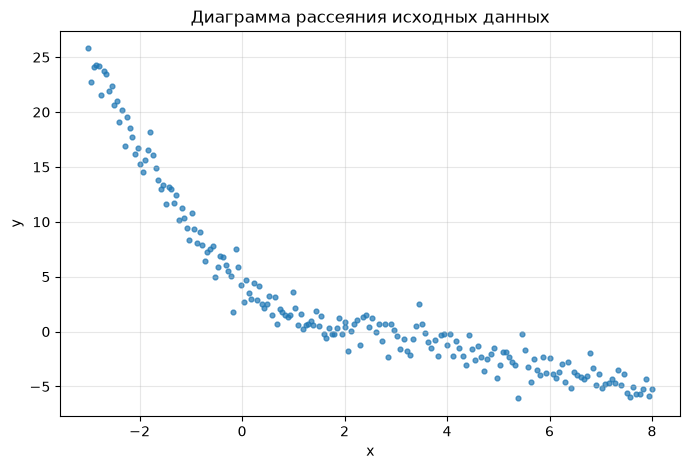

In [4]:
fig, ax = plt.subplots(figsize=(8, 5))
ax.scatter(data['x'], data['y'], s=12, alpha=0.7)
ax.set_xlabel('x')
ax.set_ylabel('y')
ax.set_title('Диаграмма рассеяния исходных данных')
ax.grid(alpha=0.3)
plt.show()

Зависимость явно нелинейная: при $x < 1$ значения $y$ резко убывают (по форме похоже на экспоненту $e^{-kx}$),
а при $x > 1$ убывание становится медленным и почти линейным, без выхода на горизонтальную асимптоту.
Поэтому кроме обычной прямой рассмотрим две модели, линейные по параметрам:

1. полиномиальную регрессию $y = \sum_{i=0}^{n} w_i x^i$;
2. регрессию на признаках $e^{-kx}$ и $x$: $y = a e^{-kx} + b x + c$.

Обе модели обучаются с помощью `LinearRegression`, нелинейность вносится через преобразование признаков.

## 3. Разбиение на обучающую и тестовую выборки

In [5]:
X = data[['x']]
y = data['y']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=RANDOM_STATE
)
print(f'Обучающая выборка: {len(X_train)}, тестовая: {len(X_test)}')

Обучающая выборка: 160, тестовая: 40


Тестовая выборка (20 %) используется только для итоговой оценки.
Гиперпараметры (степень полинома, коэффициент $k$) подбираются кросс-валидацией на обучающей выборке.

## 4–5. Выбор и обучение моделей

In [6]:
cv = KFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)


def evaluate(model, name):
    """Считает метрики модели на обучающей и тестовой выборках."""
    rows = []
    for split, X_part, y_part in [('train', X_train, y_train), ('test', X_test, y_test)]:
        pred = model.predict(X_part)
        rows.append({
            'model': name,
            'split': split,
            'MSE': mean_squared_error(y_part, pred),
            'MAE': mean_absolute_error(y_part, pred),
            'R2': r2_score(y_part, pred),
        })
    return rows

### 5.1. Базовая модель: простая линейная регрессия $y = w_1 x + w_0$

In [7]:
linear = LinearRegression().fit(X_train, y_train)
print(f'y = {linear.coef_[0]:.4f} * x + {linear.intercept_:.4f}')

y = -2.1636 * x + 8.0350


### 5.2. Полиномиальная регрессия: подбор степени

In [8]:
poly_pipeline = Pipeline([
    ('poly', PolynomialFeatures(include_bias=False)),
    ('linreg', LinearRegression()),
])
poly_search = GridSearchCV(
    poly_pipeline,
    {'poly__degree': range(1, 11)},
    scoring='neg_mean_squared_error',
    cv=cv,
)
poly_search.fit(X_train, y_train)

poly_cv = pd.DataFrame({
    'degree': poly_search.cv_results_['param_poly__degree'].astype(int),
    'cv_MSE': -poly_search.cv_results_['mean_test_score'],
})
poly_cv

,degree,cv_MSE
0,1,14.049732
1,2,4.007759
2,3,1.180182
3,4,1.102258
4,5,1.049963
5,6,1.022504
6,7,3.339814
7,8,14.594797
8,9,14.422262
9,10,19.835017


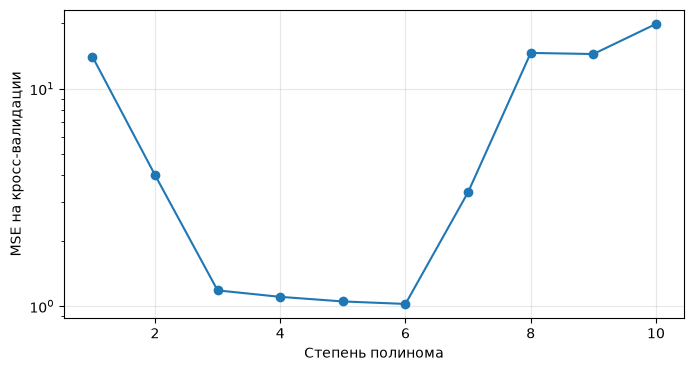

In [9]:
fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(poly_cv['degree'], poly_cv['cv_MSE'], marker='o')
ax.set_xlabel('Степень полинома')
ax.set_ylabel('MSE на кросс-валидации')
ax.set_yscale('log')
ax.grid(alpha=0.3)
plt.show()

Ошибка резко падает до степени 3, на степенях 4–6 уменьшается незначительно, а начиная со степени 7
снова растёт: полином высокой степени подстраивается под шум и сильно колеблется на краях отрезка. Возьмём наименьшую степень,
у которой ошибка на кросс-валидации отличается от минимальной не более чем на 10 %.

In [10]:
best_cv_mse = poly_cv['cv_MSE'].min()
best_degree = int(poly_cv.loc[poly_cv['cv_MSE'] <= 1.1 * best_cv_mse, 'degree'].min())
print('Выбранная степень полинома:', best_degree)

poly_model = Pipeline([
    ('poly', PolynomialFeatures(degree=best_degree, include_bias=False)),
    ('linreg', LinearRegression()),
]).fit(X_train, y_train)

Выбранная степень полинома: 4


### 5.3. Регрессия на признаках $e^{-kx}$ и $x$: подбор $k$

In [11]:
def exp_linear_features(X, k):
    """Переводит x в признаки [exp(-k*x), x]."""
    x = np.asarray(X, dtype=float).ravel()
    return np.column_stack([np.exp(-k * x), x])


exp_pipeline = Pipeline([
    ('features', FunctionTransformer(exp_linear_features, kw_args={'k': 1.0})),
    ('linreg', LinearRegression()),
])
k_grid = np.round(np.linspace(0.05, 1.5, 59), 3)
exp_search = GridSearchCV(
    exp_pipeline,
    {'features__kw_args': [{'k': k} for k in k_grid]},
    scoring='neg_mean_squared_error',
    cv=cv,
)
exp_search.fit(X_train, y_train)

best_k = exp_search.best_params_['features__kw_args']['k']
exp_model = exp_search.best_estimator_
print(f'Лучший k = {best_k}, MSE на кросс-валидации = {-exp_search.best_score_:.4f}')

Лучший k = 0.525, MSE на кросс-валидации = 1.3059


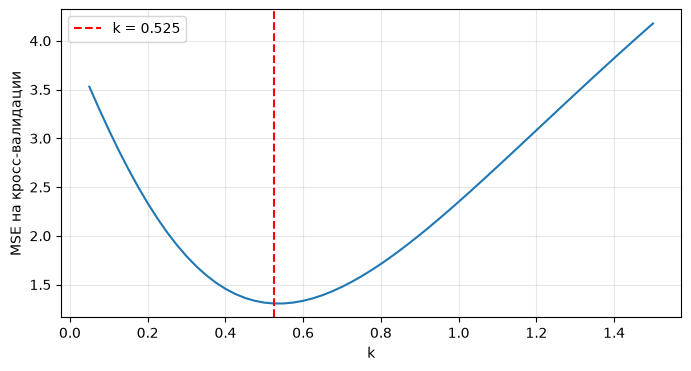

In [12]:
fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(k_grid, -exp_search.cv_results_['mean_test_score'])
ax.axvline(best_k, color='red', linestyle='--', label=f'k = {best_k}')
ax.set_xlabel('k')
ax.set_ylabel('MSE на кросс-валидации')
ax.legend()
ax.grid(alpha=0.3)
plt.show()